# OCEAVERA — Pseudo-Absence Construction

**Branch work notebook**

**Branch:** `pipeline/pseudo-absence-construction`  
**Review date:** 16 October 2026

## Contributors

Verified project identities for this branch:

<table style="width:100%; border-collapse:separate; border-spacing:1rem .2rem; margin:.45rem 0 1.25rem;">
<thead>
<tr>
<th scope="col" style="font-size:1.08em; font-weight:700; text-align:left; padding:.7rem 1rem; border-bottom:2px solid #64748b;">Registration Number</th>
<th scope="col" style="font-size:1.08em; font-weight:700; text-align:left; padding:.7rem 1rem; border-bottom:2px solid #64748b;">Member Name</th>
<th scope="col" style="font-size:1.08em; font-weight:700; text-align:left; padding:.7rem 1rem; border-bottom:2px solid #64748b;">GitHub Account</th>
</tr>
</thead>
<tbody>
<tr>
<td style="font-size:.93em; text-align:left; vertical-align:top; padding:.7rem 1rem; border-bottom:1px solid #dbe2ea;">IT24100788</td>
<td style="font-size:.93em; text-align:left; vertical-align:top; padding:.7rem 1rem; border-bottom:1px solid #dbe2ea;">Sanuda Abeysinghe</td>
<td style="font-size:.93em; text-align:left; vertical-align:top; padding:.7rem 1rem; border-bottom:1px solid #dbe2ea;"><code>sanudaabey</code></td>
</tr>
</tbody>
</table>

This notebook describes branch work. It is not an individual contribution statement or assessed reflection.

## 1. Purpose and scope

This branch implements Script 10's D-056 full-population construction. Every Policy B observation is retained as an observed presence row; a separate marine background row is paired with it for comparison.

This notebook reads the saved output and evidence for review. It does not run the construction script, change data, select model features, train models, or claim that background examples are confirmed absences. The project has not yet approved the final modelling population, accessible area, sampling policy, or target interpretation.

## 2. Data and provenance

The construction joins the existing integration chain without changing its five GeoParquets. Script 10 reads the gridded Policy B observations, the GSHHG water reference, the integration manifest, the Bio-ORACLE variable catalogue, and the matching NetCDF products.

| Item | Current result |
| --- | --- |
| Input | 2,353 gridded Policy B observations with 519 source columns |
| Output | 4,706 rows × 527 columns: 2,353 observed presences and 2,353 sampled backgrounds |
| Environmental data | 382 preserved Bio-ORACLE feature columns; missing and quarantined values remain null |
| Analysis periods | 2000–2009 → baseline 2000; 2010–2019 → baseline 2010; 2020–2026 → SSP245 2020 |
| Sampling | Seed 20261016; unique GSHHG water-cell centres; all occupied cells excluded |
| Interpretation | Label 0 is sampled background, not confirmed absence; the 1:1 ratio is not prevalence |

The **2020–2026** group uses the Bio-ORACLE SSP245 2020 slice. These are environmental period approximations, not annual measurements.

## 3. Branch result and workflow

| Artefact | Role |
| --- | --- |
| [Script 10](../../src/data_preparation/10_construct_pseudo_absences.py) | Builds the long-format candidate dataset and its construction report |
| [D-056](../../docs/records/2026-10-16-decision-paired-presence-background.md) | Records the selected construction layout and its pending scientific approvals |
| [Construction report](../../docs/records/2026-10-16-full-population-presence-background-construction.md) and [JSON evidence](../../docs/records/2026-10-16-full-population-presence-background-construction.json) | Records counts, source checks, hashes, and limitations |
| [Data dictionary](../../docs/records/2026-10-16-full-population-presence-background-data-dictionary.md) | Defines row meaning and appended fields |
| [Provisional evaluation plan](../../docs/records/2026-10-16-full-population-presence-background-evaluation-plan.md) | Lists review and validation requirements before modelling |

The earlier three-taxon D-055 experiment and superseded nested D-056 output are retained in their documented archives. This notebook only inspects the current saved files.

## 4. Read the saved result

The first code cell locates the repository from the current folder, then loads the candidate GeoParquet and report. It prints the active interpreter and the versions of packages used for this read-only review. No network access is required.

In [9]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns

ROOT = Path.cwd()
while not (ROOT / "src/data_preparation/10_construct_pseudo_absences.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Could not find the OCEAVERA repository root.")
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/interim/pseudo_absence/presence_background_candidates.parquet"
SOURCE_PATH = ROOT / "data/interim/integrated/gridded/grid_observations.parquet"
REPORT_PATH = ROOT / "docs/records/2026-10-16-full-population-presence-background-construction.json"
MASK_PATH = ROOT / "data/interim/geography/sri_lanka_marine_water.gpkg"

data = gpd.read_parquet(DATA_PATH)
report = json.loads(REPORT_PATH.read_text(encoding="utf-8"))
parquet_file = pq.ParquetFile(DATA_PATH)
geo_metadata = json.loads(parquet_file.schema_arrow.metadata[b"geo"].decode("utf-8"))
compression = sorted({
    parquet_file.metadata.row_group(0).column(i).compression
    for i in range(parquet_file.metadata.num_columns)
})

print(f"Python: {sys.version.split()[0]}")
print("Packages:", {
    name: version(name)
    for name in ("geopandas", "pandas", "pyarrow", "matplotlib", "seaborn")
})
print(f"Dataset: {DATA_PATH.relative_to(ROOT).as_posix()}")
print(f"Shape: {data.shape[0]:,} rows × {data.shape[1]:,} columns")
print(f"Size: {DATA_PATH.stat().st_size:,} bytes")
print(f"SHA-256: {hashlib.file_digest(DATA_PATH.open('rb'), 'sha256').hexdigest()}")
print(f"GeoParquet: {geo_metadata['version']}; CRS: EPSG:{data.crs.to_epsg()}; compression: {', '.join(compression)}")
print("Geometry types:", sorted(data.geometry.geom_type.dropna().unique()))
print("Sample types:", data["sample_type"].value_counts().sort_index().to_dict())

sns.set_theme(style="whitegrid", context="notebook")

Python: 3.14.8
Packages: {'geopandas': '1.2.0', 'pandas': '3.0.6', 'pyarrow': '26.0.0', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
Dataset: data/interim/pseudo_absence/presence_background_candidates.parquet
Shape: 4,706 rows × 527 columns
Size: 9,412,505 bytes
SHA-256: 234177bf3641856cdd10b425f2da957a27210f876d31092ba715a53cee7a429f
GeoParquet: 1.1.0; CRS: EPSG:4326; compression: ZSTD
Geometry types: ['Point']
Sample types: {'observed_presence': 2353, 'sampled_background': 2353}


## 5. Check paired rows and preserved source records

The checks below compare the positive rows to the saved gridded input, then verify the separate background-cell safeguards and the six core predictors. The full NetCDF comparison is reported from the construction evidence; this cell does not repeat the source-array audit.

In [10]:
source = gpd.read_parquet(SOURCE_PATH)
positive = data.loc[data["presence_background_label"].eq(1)].reset_index(drop=True)
background = data.loc[data["presence_background_label"].eq(0)].reset_index(drop=True)

for column in source.columns:
    pd.testing.assert_series_equal(
        positive[column].reset_index(drop=True),
        source[column].reset_index(drop=True),
        check_dtype=False,
        check_names=False,
    )

assert positive.geometry.equals(source.geometry.reset_index(drop=True))
assert data["sample_id"].is_unique

occupied_cells = set(source["grid_cell_id"].astype("int64"))
background_cells = set(background["grid_cell_id"].astype("int64"))
assert len(background_cells) == len(background)
assert occupied_cells.isdisjoint(background_cells)

core_predictors = [
    "bio_oracle__thetao_mean__depthsurf",
    "bio_oracle__so_mean__depthsurf",
    "bio_oracle__o2_mean__depthsurf",
    "bio_oracle__chl_mean__depthsurf",
    "bio_oracle__ph_mean__depthsurf",
    "bio_oracle__bathymetry_mean__benthic",
]
assert background[core_predictors].notna().all().all()

print(f"Positive rows match all {len(source.columns)} saved input columns and geometries.")
print(f"Unique background cells: {len(background_cells):,}; occupied-cell overlap: 0")
print(f"Background rows with all six core predictors: {background[core_predictors].notna().all(axis=1).sum():,}")

Positive rows match all 519 saved input columns and geometries.
Unique background cells: 2,353; occupied-cell overlap: 0
Background rows with all six core predictors: 2,353


## 6. Compare class counts by period

Each source period has a one-to-one number of observed positive rows and sampled background rows. The chart describes the construction balance; it does not represent prevalence.

sample_type,observed_presence,sampled_background
analysis_period,,
2000-2009,376,376
2010-2019,596,596
2020-2026,1381,1381


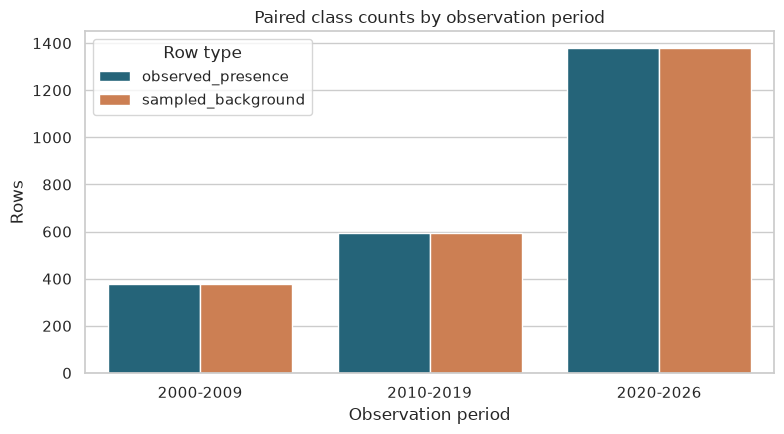

In [11]:
period_order = ["2000-2009", "2010-2019", "2020-2026"]
class_period = (
    data.groupby(["analysis_period", "sample_type"], observed=True)
    .size()
    .reset_index(name="rows")
)
display(class_period.pivot(index="analysis_period", columns="sample_type", values="rows").reindex(period_order))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=class_period,
    x="analysis_period",
    y="rows",
    hue="sample_type",
    order=period_order,
    hue_order=["observed_presence", "sampled_background"],
    palette={"observed_presence": "#176B87", "sampled_background": "#E07A3F"},
    ax=ax,
)
ax.set(title="Paired class counts by observation period", xlabel="Observation period", ylabel="Rows")
ax.legend(title="Row type")
plt.tight_layout()
plt.show()

## 7. Review preliminary eligibility

The technical eligibility flag is a screening aid, not taxonomic verification or evidence of sample adequacy. Reason counts can overlap because one positive row can fail more than one condition.

eligible_species_level_ml,False,True
analysis_period,,
2000-2009,215,161
2010-2019,153,443
2020-2026,256,1125


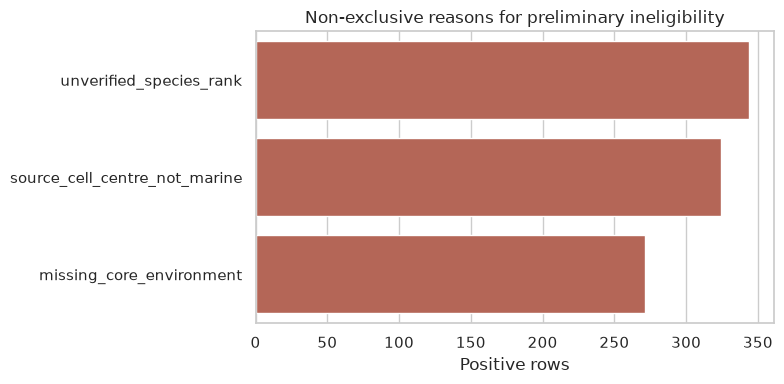

In [12]:
eligibility_by_period = (
    positive.groupby(["analysis_period", "eligible_species_level_ml"], observed=True)
    .size()
    .reset_index(name="rows")
)
display(eligibility_by_period.pivot(
    index="analysis_period",
    columns="eligible_species_level_ml",
    values="rows",
).reindex(period_order))

reason_counts = report["species_level_eligibility"]["ineligible_reason_counts_nonexclusive"]
reasons = pd.DataFrame(
    {"reason": list(reason_counts), "rows": list(reason_counts.values())}
).sort_values("rows", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=reasons, x="rows", y="reason", color="#C45B47", ax=ax)
ax.set(title="Non-exclusive reasons for preliminary ineligibility", xlabel="Positive rows", ylabel="")
plt.tight_layout()
plt.show()

## 8. Map positive and background locations

This map compares the recorded positive locations with the sampled marine-water cell centres against the saved GSHHG water polygon. It shows sampling geography; it does not estimate species ranges or validate an ecological accessible area.

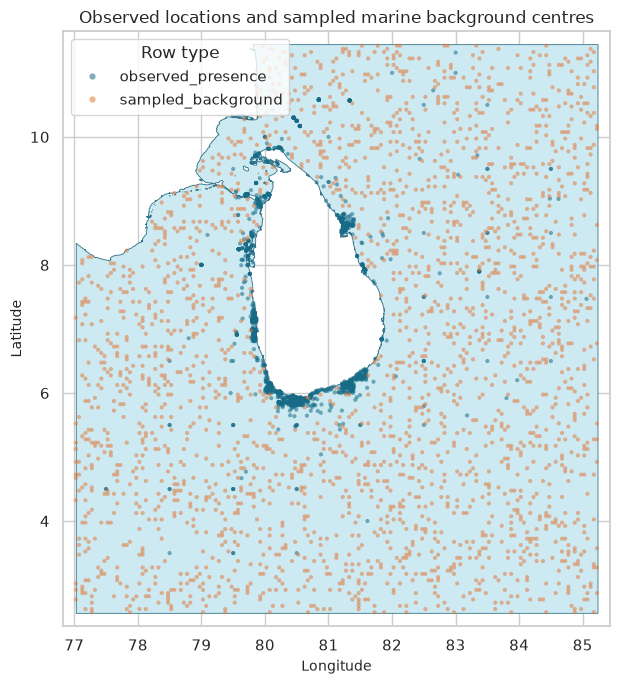

In [13]:
water = gpd.read_file(MASK_PATH).to_crs(data.crs)
points = data.assign(
    longitude=data.geometry.x,
    latitude=data.geometry.y,
)

fig, ax = plt.subplots(figsize=(8, 7))
water.plot(ax=ax, color="#CDEAF2", edgecolor="#35758A", linewidth=0.6)
sns.scatterplot(
    data=points,
    x="longitude",
    y="latitude",
    hue="sample_type",
    hue_order=["observed_presence", "sampled_background"],
    palette={"observed_presence": "#176B87", "sampled_background": "#E07A3F"},
    s=9,
    alpha=0.55,
    linewidth=0,
    ax=ax,
)
xmin, ymin, xmax, ymax = water.total_bounds
ax.set(xlim=(xmin - 0.2, xmax + 0.2), ylim=(ymin - 0.2, ymax + 0.2))
ax.set(title="Observed locations and sampled marine background centres", xlabel="Longitude", ylabel="Latitude")
ax.legend(title="Row type", markerscale=1.5)
plt.tight_layout()
plt.show()

## 9. Check core-feature coverage

Background sampling required complete values for the six core predictors. Positive observations with missing values remain in the candidate dataset; no values are imputed here.

,predictor,sample_type,non_null,total,percent
0,bio_oracle__bathymetry_mean__benthic,observed_presence,2082,2353,88.482788
1,bio_oracle__bathymetry_mean__benthic,sampled_background,2353,2353,100.000000
2,bio_oracle__chl_mean__depthsurf,observed_presence,2082,2353,88.482788
3,bio_oracle__chl_mean__depthsurf,sampled_background,2353,2353,100.000000
4,bio_oracle__o2_mean__depthsurf,observed_presence,2082,2353,88.482788
5,bio_oracle__o2_mean__depthsurf,sampled_background,2353,2353,100.000000
6,bio_oracle__ph_mean__depthsurf,observed_presence,2082,2353,88.482788
7,bio_oracle__ph_mean__depthsurf,sampled_background,2353,2353,100.000000
8,bio_oracle__so_mean__depthsurf,observed_presence,2082,2353,88.482788
9,bio_oracle__so_mean__depthsurf,sampled_background,2353,2353,100.000000


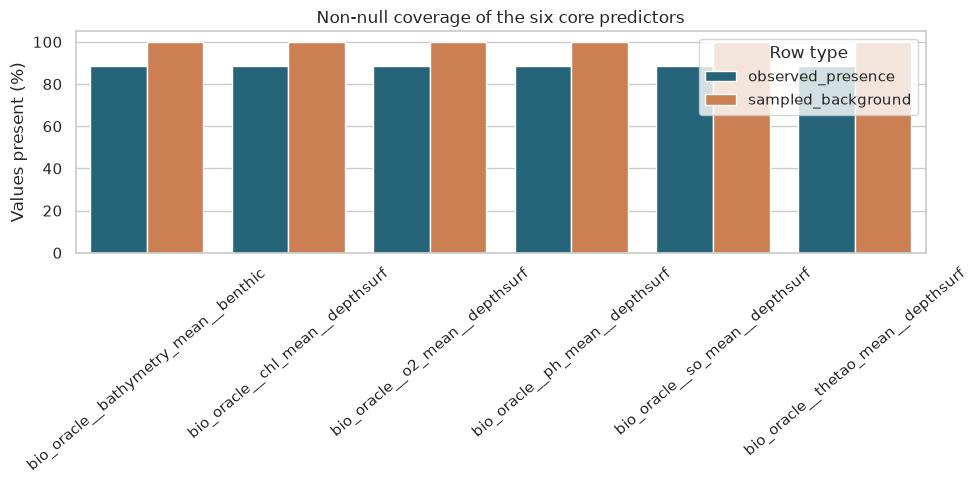

In [14]:
coverage = (
    data.melt(
        id_vars="sample_type",
        value_vars=core_predictors,
        var_name="predictor",
        value_name="value",
    )
    .groupby(["predictor", "sample_type"], observed=True)["value"]
    .agg(non_null="count", total="size")
    .reset_index()
)
coverage["percent"] = 100 * coverage["non_null"] / coverage["total"]
display(coverage[["predictor", "sample_type", "non_null", "total", "percent"]])

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=coverage,
    x="predictor",
    y="percent",
    hue="sample_type",
    hue_order=["observed_presence", "sampled_background"],
    palette={"observed_presence": "#176B87", "sampled_background": "#E07A3F"},
    ax=ax,
)
ax.set(title="Non-null coverage of the six core predictors", xlabel="", ylabel="Values present (%)")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Row type")
plt.tight_layout()
plt.show()

## 10. Compare bathymetry distributions

Bathymetry differs between the recorded occurrence locations and the uniform water-cell sample. The empirical distributions are descriptive and highlight a comparability risk for any later classifier.

,sample_type,non_null,median
0,observed_presence,2082,-15.888889
1,sampled_background,2353,-3771.611084


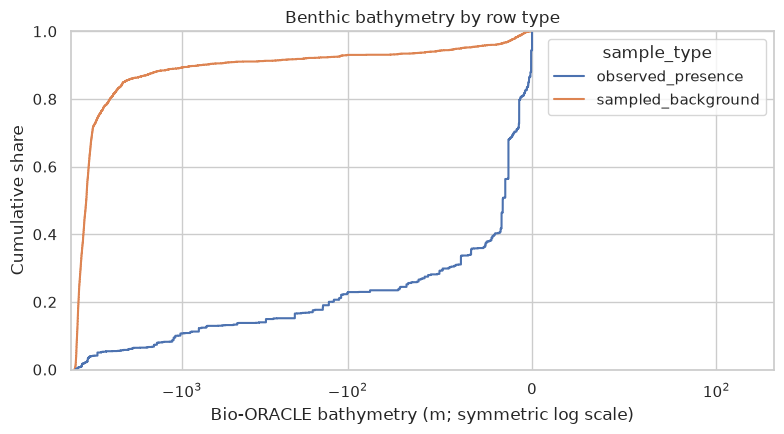

In [15]:
bathymetry = "bio_oracle__bathymetry_mean__benthic"
bathymetry_summary = (
    data.groupby("sample_type", observed=True)[bathymetry]
    .agg(non_null="count", median="median")
    .reset_index()
)
display(bathymetry_summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.ecdfplot(data=data, x=bathymetry, hue="sample_type", ax=ax)
ax.set_xscale("symlog", linthresh=100)
ax.set(title="Benthic bathymetry by row type", xlabel="Bio-ORACLE bathymetry (m; symmetric log scale)", ylabel="Cumulative share")
plt.tight_layout()
plt.show()

## 11. Read the construction verification evidence

Script 10's report records the source-product check. These results are reported evidence from that construction run, not a second independent NetCDF audit performed by this notebook.

In [16]:
environment_check = report["source_environment_verification"]
spatial_check = report["spatial_validation"]
source_grid_check = spatial_check["source_grid_checks"]

print(f"Bio-ORACLE products checked: {environment_check['netcdf_products_verified']}")
print(f"Catalogue mappings checked: {environment_check['source_variable_mappings_checked']:,}")
print(f"Background environmental positions: {environment_check['background_positions_checked']:,}")
print(f"Numerical mismatches: {environment_check['numerical_mismatches']}")
print(f"Null/fill discrepancies: {environment_check['null_fill_discrepancies']}")
print(f"Maximum absolute difference: {environment_check['maximum_absolute_difference']}")
print(f"Source-axis index / centre discrepancies: {source_grid_check['raster_index_discrepancies']} / {source_grid_check['raster_centre_discrepancies']}")
print(f"Background centres in GSHHG water: {spatial_check['background_centres_inside_gshhg_water']:,}")
print(f"Five integration GeoParquets preserved: {report['source_preservation']['all_five_integration_datasets_byte_identical']}")

period_checks = pd.DataFrame(environment_check["by_period"])
display(period_checks[[
    "analysis_period",
    "environment_period",
    "positions_checked",
    "numerical_mismatches",
    "null_fill_discrepancies",
    "maximum_absolute_difference",
]])

Bio-ORACLE products checked: 106
Catalogue mappings checked: 1,012
Background environmental positions: 898,846
Numerical mismatches: 0
Null/fill discrepancies: 0
Maximum absolute difference: 0.0
Source-axis index / centre discrepancies: 0 / 0
Background centres in GSHHG water: 2,353
Five integration GeoParquets preserved: True


,analysis_period,environment_period,positions_checked,numerical_mismatches,null_fill_discrepancies,maximum_absolute_difference
0,2000-2009,baseline_2000,143632,0,0,0.0
1,2010-2019,baseline_2010,227672,0,0,0.0
2,2020-2026,ssp245_2020,527542,0,0,0.0


## 12. Findings, limits, and next authorised work

- Script 10 retains the full 2,353-row Policy B population and pairs it with 2,353 distinct marine background cells.
- The 1:1 class balance is a construction choice and does not describe real species prevalence.
- The 2020–2026 rows use the SSP245 2020 environmental slice, not annual future observations.
- Broad uniform water sampling differs geographically and by depth from the occurrence sample. It may let a model separate sampling locations instead of species habitat.
- Repeated records and shared raster cells require spatially grouped validation across periods and taxa. No model table, feature selection, imputation, split, model, or evaluation was created here.
- The target population, accessible area, sampling design, species eligibility, and validation protocol remain subject to group review.

Next work requires the relevant group decisions and the EDA/preprocessing and spatial-validation workflow gates. See [PROJECT_REQUIREMENTS.md](../../PROJECT_REQUIREMENTS.md), the [workflow](../../docs/ml/ml-workflow-and-evidence-gates.md), the [evaluation plan](../../docs/records/2026-10-16-full-population-presence-background-evaluation-plan.md), and the [current readiness review](../../docs/project/repository-readiness-and-alignment.md).